In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/healthcare-analytics-capstone"
)

RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
IMAGES = PROJECT / "images"
REPORTS = PROJECT / "reports"

PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

print("ICU notebook setup complete!")

ICU notebook setup complete!


In [3]:
icu_summary = pd.read_excel(
    RAW / "ICU_Sepsis_Patient_Summary.xlsx"
)

icu_clinical = pd.read_excel(
    RAW / "ICU_Sepsis_Patient_Data.xlsx"
)

icu_dictionary = pd.read_excel(
    RAW / "ICU_Sepsis_Patient_Data_Dictionary.xlsx"
)

print("ICU summary:", icu_summary.shape)
print("Clinical data:", icu_clinical.shape)
print("Dictionary:", icu_dictionary.shape)

display(icu_summary.head())
display(icu_clinical.head())
display(icu_dictionary)

ICU summary: (180, 6)
Clinical data: (180, 18)
Dictionary: (18, 3)


,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour
0,ICU0001,58,Female,66,1,33.0
1,ICU0002,41,Female,50,1,44.0
2,ICU0003,57,Male,38,0,NaN
3,ICU0004,79,Female,28,0,NaN
4,ICU0005,60,Male,49,1,38.0


,patient_id,age,gender,los_hours,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0


,column,category,description
0,patient_id,Identifier,Unique ICU patient identifier
1,age,Demographic,Patient age in years
2,gender,Demographic,Patient gender
3,los_hours,Operational,ICU length of stay in hours
4,heart_rate_bpm,Vital sign,Heart rate in beats per minute
5,systolic_bp_mmhg,Vital sign,Systolic blood pressure in mmHg
6,respiratory_rate_bpm,Vital sign,Respiratory rate in breaths per minute
7,temperature_c,Vital sign,Body temperature in degrees Celsius
8,spo2_percent,Vital sign,Peripheral oxygen saturation percentage
9,wbc_10e9_l,Laboratory,White blood cell count


In [4]:
assert not icu_summary["patient_id"].duplicated().any()
assert not icu_clinical["patient_id"].duplicated().any()

assert set(icu_summary["patient_id"]) == set(
    icu_clinical["patient_id"]
)

shared_columns = ["age", "gender", "los_hours"]

check = icu_summary[
    ["patient_id"] + shared_columns
].merge(
    icu_clinical[
        ["patient_id"] + shared_columns
    ],
    on="patient_id",
    suffixes=("_summary", "_clinical"),
    validate="one_to_one"
)

for column in shared_columns:
    assert (
        check[f"{column}_summary"]
        == check[f"{column}_clinical"]
    ).all(), f"Mismatch in {column}"

print("ICU patient records match!")

ICU patient records match!


In [5]:
icu = icu_summary.merge(
    icu_clinical.drop(columns=shared_columns),
    on="patient_id",
    how="inner",
    validate="one_to_one"
)

print("Merged ICU shape:", icu.shape)

display(icu.head())

Merged ICU shape: (180, 20)


,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,1,33.0,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,1,44.0,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,0,NaN,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,0,NaN,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,1,38.0,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0


In [6]:
print("Duplicate rows:", icu.duplicated().sum())

print("Missing values:")
display(icu.isnull().sum())

print("Sepsis outcomes:")
display(icu["developed_sepsis"].value_counts())

print("Missing onset times by outcome:")
display(
    pd.crosstab(
        icu["developed_sepsis"],
        icu["sepsis_onset_hour"].isna()
    )
)

Duplicate rows: 0
Missing values:


,0
patient_id,0
age,0
gender,0
los_hours,0
developed_sepsis,0
sepsis_onset_hour,130
heart_rate_bpm,0
systolic_bp_mmhg,0
respiratory_rate_bpm,0
temperature_c,4


Sepsis outcomes:


,count
developed_sepsis,
0,130
1,50


Missing onset times by outcome:


sepsis_onset_hour,False,True
developed_sepsis,,
0,0,130
1,50,0


In [7]:
# Clinical columns with missing measurements
clinical_columns = [
    "temperature_c",
    "wbc_10e9_l",
    "lactate_mmol_l",
    "creatinine_mg_dl",
    "urine_output_ml_kg_hr"
]

# Compare missing values by sepsis outcome
for column in clinical_columns:
    print(f"\nMissing values in {column}")

    display(
        pd.crosstab(
            icu["developed_sepsis"],
            icu[column].isna()
        )
    )


Missing values in temperature_c


temperature_c,False,True
developed_sepsis,,
0,127,3
1,49,1



Missing values in wbc_10e9_l


wbc_10e9_l,False,True
developed_sepsis,,
0,128,2
1,46,4



Missing values in lactate_mmol_l


lactate_mmol_l,False,True
developed_sepsis,,
0,123,7
1,49,1



Missing values in creatinine_mg_dl


creatinine_mg_dl,False,True
developed_sepsis,,
0,128,2
1,47,3



Missing values in urine_output_ml_kg_hr


urine_output_ml_kg_hr,False,True
developed_sepsis,,
0,124,6
1,49,1


In [9]:
# Count missing clinical measurements for each patient
missing_per_patient = (
    icu[clinical_columns].isna().sum(axis=1)
)

print(
    "Patients with at least one missing measurement:",
    (missing_per_patient > 0).sum()
)

print(
    "Patients with complete clinical measurements:",
    (missing_per_patient == 0).sum()
)

print(
    "Total missing clinical entries:",
    missing_per_patient.sum()
)

Patients with at least one missing measurement: 27
Patients with complete clinical measurements: 153
Total missing clinical entries: 30


In [10]:
icu_clean = icu.copy()

icu_clean.to_csv(
    PROCESSED / "icu_clean.csv",
    index=False
)

print("ICU working dataset saved!")

ICU working dataset saved!


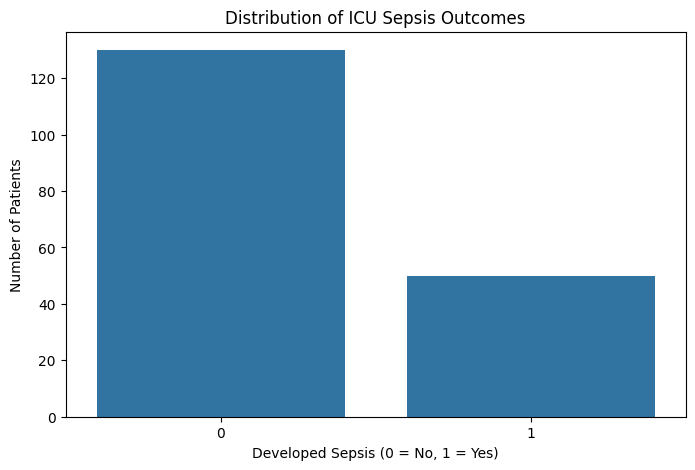

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=icu_clean,
    x="developed_sepsis"
)

plt.title("Distribution of ICU Sepsis Outcomes")
plt.xlabel("Developed Sepsis (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.savefig(
    IMAGES / "icu_sepsis_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
display(
    icu_clean.groupby("developed_sepsis")[
        ["age", "los_hours"]
    ].agg(["mean", "median", "std"])
)

age                    los_hours                  
                       mean median        std       mean median        std
developed_sepsis                                                          
0                 57.269231   58.0  16.992834  39.046154   36.5  17.128272
1                 57.220000   58.5  16.376053  43.340000   47.0  17.549475

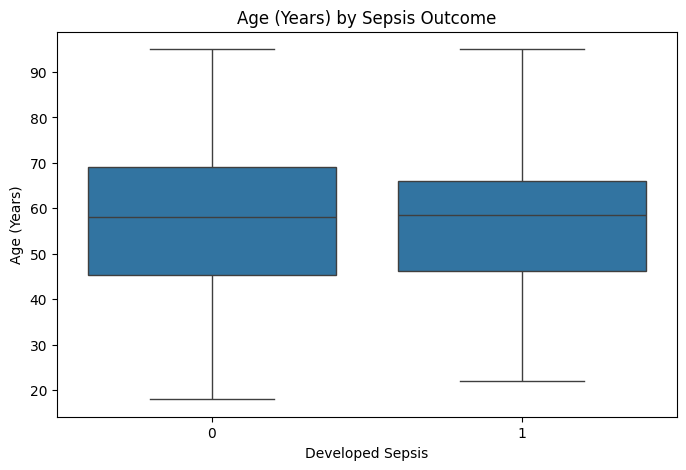

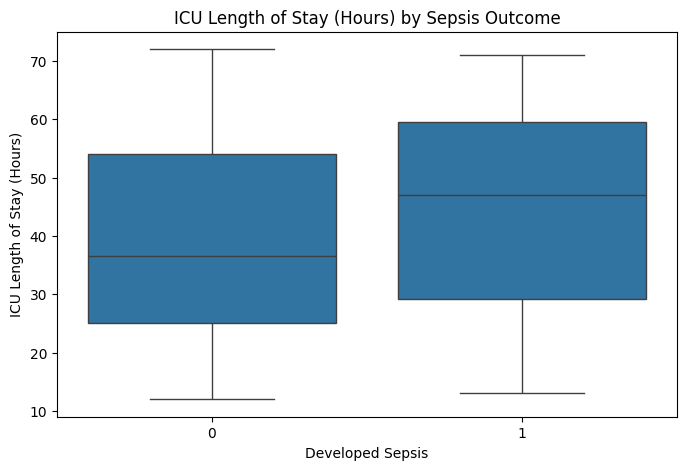

In [13]:
for variable, label in [
    ("age", "Age (Years)"),
    ("los_hours", "ICU Length of Stay (Hours)")
]:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=icu_clean,
        x="developed_sepsis",
        y=variable
    )

    plt.title(f"{label} by Sepsis Outcome")
    plt.xlabel("Developed Sepsis")
    plt.ylabel(label)

    plt.savefig(
        IMAGES / f"icu_{variable}_by_outcome.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

In [14]:
display(
    pd.crosstab(
        icu_clean["gender"],
        icu_clean["developed_sepsis"],
        normalize="index"
    ) * 100
)

developed_sepsis,0,1
gender,,
Female,74.193548,25.806452
Male,70.114943,29.885057


In [15]:
sepsis_cases = icu_clean[
    icu_clean["developed_sepsis"] == 1
]

display(
    sepsis_cases["sepsis_onset_hour"].describe()
)

,sepsis_onset_hour
count,50.000000
mean,21.200000
std,12.600615
min,6.000000
25%,11.000000
50%,17.500000
75%,30.750000
max,51.000000


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

X = icu_clean[["age", "gender"]]

y = icu_clean["developed_sepsis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer([
    (
        "age",
        SimpleImputer(strategy="median"),
        ["age"]
    ),
    (
        "gender",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        ["gender"]
    )
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

    trained_models[name] = pipeline

icu_results = pd.DataFrame(results)

display(icu_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,False Negatives,False Positives
0,Logistic Regression,0.722,0.000,0.0,0.000,0.379,10,0
1,Decision Tree,0.694,0.333,0.1,0.154,0.473,9,2
2,Random Forest,0.722,0.500,0.1,0.167,0.475,9,1


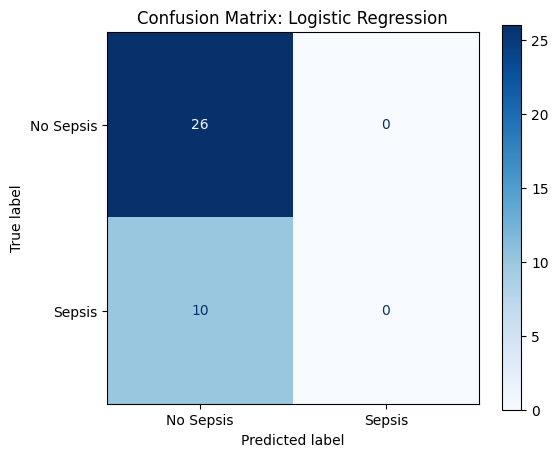

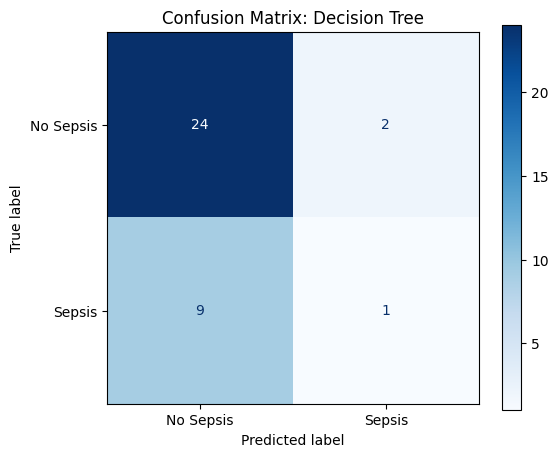

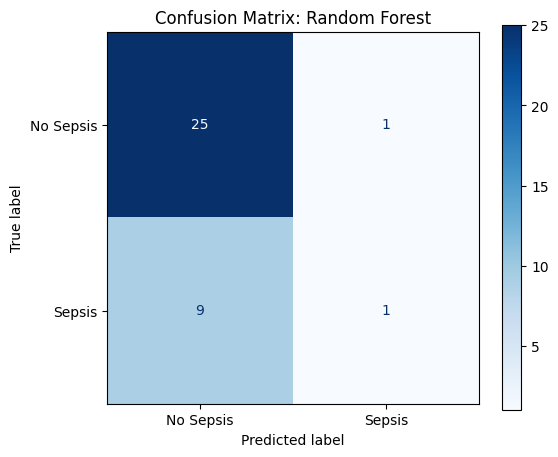

In [17]:
for name, model in trained_models.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No Sepsis", "Sepsis"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"Confusion Matrix: {name}")

    filename = (
        name.lower().replace(" ", "_") +
        "_confusion_matrix.png"
    )

    fig.savefig(
        IMAGES / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

In [18]:
icu_results.to_csv(
    PROCESSED / "icu_model_comparison.csv",
    index=False
)

print("ICU model comparison saved!")

ICU model comparison saved!
